In [ ]:
!pip install crepe
!pip install opensmile
!pip install textgrid

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 54.7 MB/s eta 0:00:00
  Created wheel for crepe: filename=crepe-0.0.16-py3-none-any.whl size=134848777 sha256=0af0eb247454db8eb00cff896c02988fd3a85d8ac523cd75fdebe728eaac9ad9
  Stored in directory: /root/.cache/pip/wheels/60/fe/bc/ee65c6a42d211eb94001b747c856fe594c6318f21bbae09f89
Successfully built crepe
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.7/133.7 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 33.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for textgrid: filename=textgrid-1.6.1-py3-none-any.whl size=10217 sha256=2bbccb572d00c369136a18d9f893c51d557d72c0c548578e0877333528432d5e
  Stor

In [ ]:
import numpy as np
import librosa
import crepe
import os
from tqdm import tqdm
import json
import glob
import pandas as pd
import opensmile
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import f_oneway
import tensorflow as tf
from scipy.stats import entropy
import textgrid
import re

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# RAVDESS

**SETUP**

1. Unzip the RAVDESS dataset so that all audio files are located under:
/content/drive/MyDrive/RAVDESS/
2. Unzip the 'mfa_results.zip' so that all files are located under: /content/drive/MyDrive/mfa_results/


In [ ]:
target_sr = 22050
n_mels = 160
hop_length = 256
n_fft = 2048
target_frames = 128

In [ ]:
def compute_mfdr_singing(f0, conf, step_size_ms=10,
                         low_band=(0.5, 3), vib_band=(4, 8), high_band=(8, 20)):
    """
    Calculates modulation frequency domain ratios for the singing pitch contour.
    Bands:
    - 0.5–3 Hz: slow expressive modulations / phrasing
    - 4–8 Hz: vibrato region
    - 8–20 Hz: micro-modulations / stress / noise
    """
    if len(f0) < 20:
        return {k: np.nan for k in [
            "MFDR_slow", "MFDR_vibrato", "MFDR_high",
            "MFDR_slow2vibrato", "MFDR_vibrato2high"
        ]}

    # Convert to semitones for a constant scale
    st = 12 * np.log2(f0 / 55.0)
    st = st - np.mean(st)

    fs_feat = 1000.0 / step_size_ms  # frame rate
    spec = np.fft.rfft(st)
    freqs = np.fft.rfftfreq(len(st), d=1/fs_feat)
    mag2 = np.abs(spec)**2

    def band_energy(lo, hi):
        mask = (freqs >= lo) & (freqs < hi)
        return np.sum(mag2[mask])

    e_total = band_energy(0.5, 20)
    e_slow = band_energy(*low_band)
    e_vib  = band_energy(*vib_band)
    e_high = band_energy(*high_band)

    return {
        "MFDR_slow": e_slow / e_total,
        "MFDR_vibrato": e_vib / e_total,
        "MFDR_high": e_high / e_total,
        "MFDR_slow2vibrato": (e_slow + 1e-12) / (e_vib + 1e-12),
        "MFDR_vibrato2high": (e_vib + 1e-12) / (e_high + 1e-12)
    }

In [ ]:
def parse_ravdess_filename(filename):
    base = os.path.basename(filename)
    base = os.path.splitext(base)[0]
    parts = base.split('-')
    metadata = {
        'modality': int(parts[0]),
        'vocal_channel': int(parts[1]),
        'emotion': int(parts[2]),
        'intensity': int(parts[3]),
        'statement': int(parts[4]),
        'repetition': int(parts[5]),
        'actor_id': int(parts[6]),
        'gender': 'male' if int(parts[6]) % 2 == 1 else 'female'
    }
    return metadata

def extract_extra_features(y, sr):

    # ---------- Spectral Flatness ----------
    flatness = librosa.feature.spectral_flatness(y=y)[0]
    spectral_flatness_mean = np.mean(flatness)
    spectral_flatness_std = np.std(flatness)

    # ---------- Spectral Centroid ----------
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    spectral_centroid_mean = np.mean(centroid)
    spectral_centroid_std = np.std(centroid)

    # ---------- Zero Crossing Rate (ZCR) ----------
    zcr = librosa.feature.zero_crossing_rate(y=y)[0]
    zcr_mean = np.mean(zcr)
    zcr_std = np.std(zcr)

    # ---------- Loudness (RMS) & Energy ----------
    rms = librosa.feature.rms(y=y)[0]
    st_loud_var = np.mean(np.abs(np.diff(rms)))
    lt_loud_var = np.max(rms) - np.min(rms)
    delta_energy = np.diff(rms)

    try:
        # CREPE Pitch Tracking
        time, f0, conf, _ = crepe.predict(y, sr, model_capacity="medium", step_size=10, verbose=False)

        f0_flat = f0.flatten()
        conf_flat = conf.flatten()

        # Keep valid frames only
        mask = conf_flat > 0.7
        f0_voiced = f0_flat[mask]

        if len(f0_voiced) > 10:
            st = 12 * np.log2(f0_voiced / 440.0)

            # 1. Melodic & Variability Features
            pitch_variability = np.std(st)
            melodic_deviation = np.mean(np.abs(st - np.mean(st)))

            # 2. Absolute Deviation
            abs_dett_array = np.abs(st - np.round(st))
            dett_mean = np.mean(abs_dett_array)
            dett_sd = np.std(abs_dett_array)

            # 3. Signed Deviation
            signed_dett_array = st - np.round(st)
            pitch_bias = np.mean(signed_dett_array)

            # 4. Coefficient of Variation
            dett_cv = dett_sd / dett_mean if dett_mean > 0 else 0

            # 5. Delta Pitch
            delta_pitch = np.diff(st)
            delta_pitch_mean = np.mean(delta_pitch)
            delta_pitch_std = np.std(delta_pitch)

            # Segmentation Logic for MFDR
            segments = []
            current_segment = []

            for val, c in zip(f0_flat, conf_flat):
                if c > 0.7:
                    current_segment.append(val)
                else:
                    if len(current_segment) >= 20: # at least 200ms segments
                        segments.append(np.array(current_segment))
                    current_segment = []

            if len(current_segment) >= 20:
                segments.append(np.array(current_segment))

            # Calculate MFDR per segment and compute average
            mfdr_list = []
            for seg in segments:
                res = compute_mfdr_singing(seg, conf=None, step_size_ms=10)
                if not np.isnan(res["MFDR_slow"]):
                    mfdr_list.append(res)

            if mfdr_list:
                mfdr_features = {}
                for key in mfdr_list[0].keys():
                    mfdr_features[key] = np.mean([r[key] for r in mfdr_list])
            else:
                mfdr_features = {k: np.nan for k in ["MFDR_slow", "MFDR_vibrato", "MFDR_high", "MFDR_slow2vibrato", "MFDR_vibrato2high"]}

        else:
            melodic_deviation = pitch_variability = dett_mean = dett_sd = pitch_bias = dett_cv = delta_pitch_mean = delta_pitch_std = np.nan
            mfdr_features = {k: np.nan for k in ["MFDR_slow", "MFDR_vibrato", "MFDR_high", "MFDR_slow2vibrato", "MFDR_vibrato2high"]}

    except Exception as e:
        print(f"CREPE error: {e}")
        melodic_deviation = pitch_variability = dett_mean = dett_sd = pitch_bias = delta_pitch_mean = delta_pitch_std = dett_cv = np.nan
        mfdr_features = {k: np.nan for k in ["MFDR_slow", "MFDR_vibrato", "MFDR_high", "MFDR_slow2vibrato", "MFDR_vibrato2high"]}

    return {
        "melodic_deviation": melodic_deviation,
        "pitch_variability": pitch_variability,
        "dett_mean": dett_mean,
        "dett_std": dett_sd,
        "dett_cv": dett_cv,
        "pitch_bias": pitch_bias,
        "delta_pitch_mean": delta_pitch_mean,
        "delta_pitch_std": delta_pitch_std,
        "spectral_flatness_mean": spectral_flatness_mean,
        "spectral_flatness_std": spectral_flatness_std,
        "spectral_centroid_mean": spectral_centroid_mean,
        "spectral_centroid_std": spectral_centroid_std,
        "st_loudness_variability": st_loud_var,
        "lt_loudness_variability": lt_loud_var,
        "zcr_mean": zcr_mean,
        "zcr_std": zcr_std,
        "delta_energy_mean": np.mean(delta_energy),
        "delta_energy_std": np.std(delta_energy),
        **mfdr_features
    }

In [ ]:
# recursively search directories
drive_path = "/content/drive/MyDrive/RAVDESS/**/*.wav"

smile = opensmile.Smile(
    feature_set=opensmile.FeatureSet.eGeMAPSv02,
    feature_level=opensmile.FeatureLevel.Functionals
)

all_features = []

for wave_file in tqdm(glob.glob(drive_path, recursive=True), desc="Processing files"):
    file_name_only = os.path.basename(wave_file)

    try:
        y, sr = librosa.load(wave_file, sr=target_sr)
        metadata = parse_ravdess_filename(file_name_only)

        # --- OpenSMILE ---
        features = smile.process_signal(y, sr)
        opensmile_features = features.iloc[0].to_dict()

        # --- Extra Features ---
        extra_features = extract_extra_features(y, sr)

        # Combine data
        combined_features = {**metadata, **opensmile_features, **extra_features}
        combined_features["filename"] = file_name_only
        combined_features["full_path"] = wave_file

        all_features.append(combined_features)

    except Exception as e:
        print(f"Error processing {wave_file}: {e}")

df_features = pd.DataFrame(all_features)

Processing files: 100%|██████████| 1012/1012 [20:17<00:00,  1.20s/it]


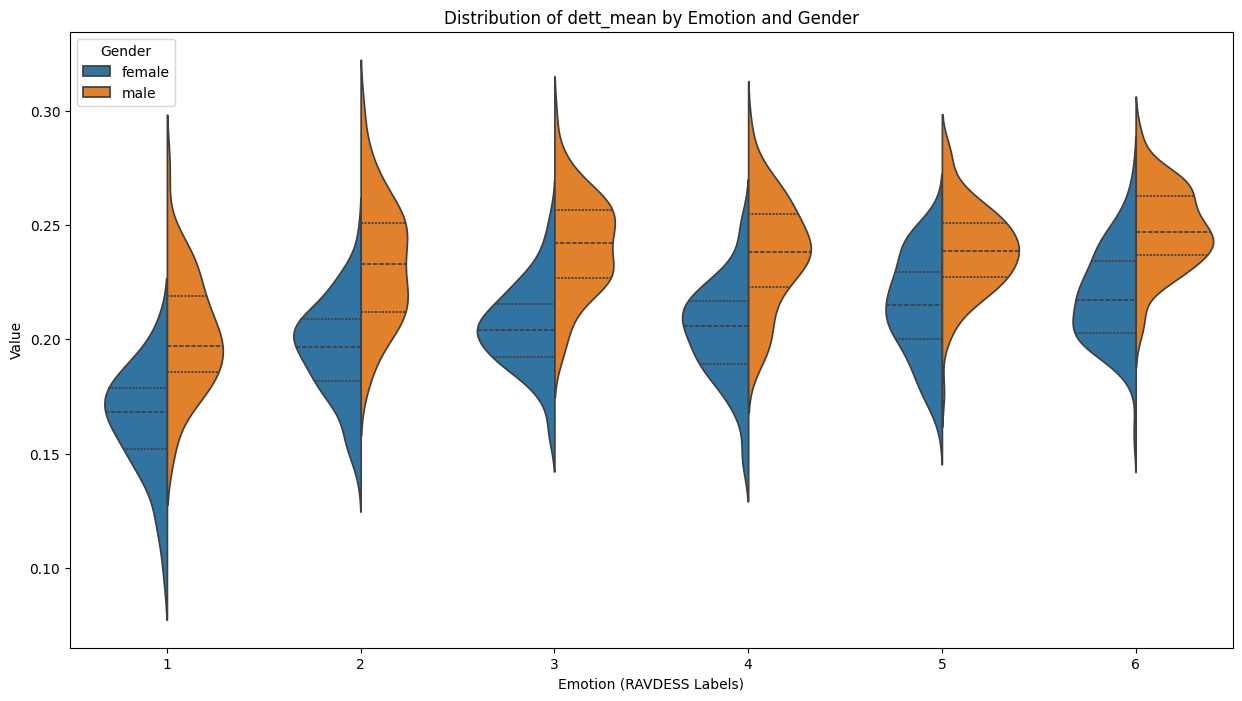

In [ ]:
feature_to_check = 'dett_mean' # Examine proxy deviation from target tone

plt.figure(figsize=(15, 8))
sns.violinplot(x='emotion', y=feature_to_check, hue='gender', data=df_features, split=True, inner="quart")

plt.title(f'Distribution of {feature_to_check} by Emotion and Gender')
plt.xlabel('Emotion (RAVDESS Labels)')
plt.ylabel('Value')
plt.legend(title='Gender')
plt.show()

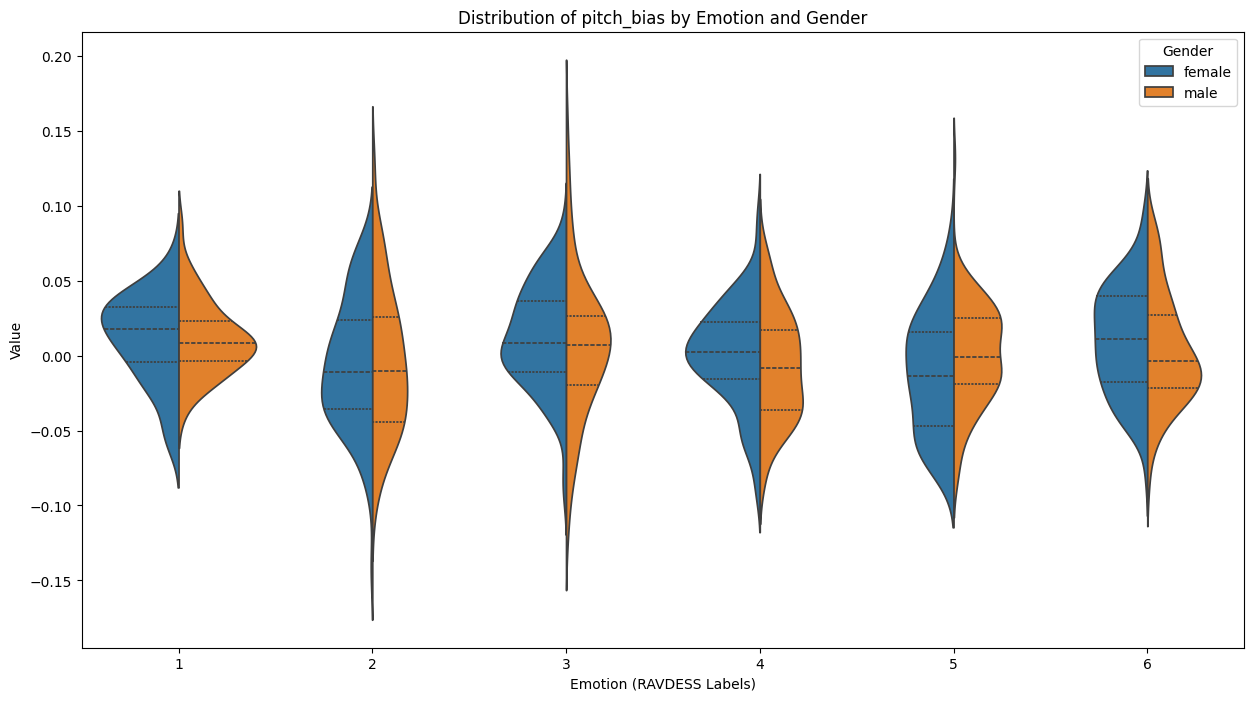

In [ ]:
feature_to_check = 'pitch_bias'

plt.figure(figsize=(15, 8))
sns.violinplot(x='emotion', y=feature_to_check, hue='gender', data=df_features, split=True, inner="quart")

plt.title(f'Distribution of {feature_to_check} by Emotion and Gender')
plt.xlabel('Emotion (RAVDESS Labels)')
plt.ylabel('Value')
plt.legend(title='Gender')
plt.show()

In [ ]:
emotions = df_features['emotion'].unique()
feature = 'MFDR_vibrato'

groups = [df_features[df_features['emotion'] == e][feature].dropna() for e in emotions]
f_stat, p_val = f_oneway(*groups)

print(f"Feature: {feature}")
print(f"F-statistic: {f_stat:.2f}")
print(f"p-value: {p_val:.4e}")

if p_val < 0.05:
    print("Statistically Significant! This feature is useful")

Feature: MFDR_vibrato
F-statistic: 9.82
p-value: 3.5765e-09
Statistically Significant! This feature is useful


In [ ]:
emotions = df_features['emotion'].unique()
feature = 'dett_mean'

groups = [df_features[df_features['emotion'] == e][feature].dropna() for e in emotions]
f_stat, p_val = f_oneway(*groups)

print(f"Feature: {feature}")
print(f"F-statistic: {f_stat:.2f}")
print(f"p-value: {p_val:.4e}")

if p_val < 0.05:
    print("Statistically Significant! This feature is useful")

Feature: dett_mean
F-statistic: 46.71
p-value: 1.7538e-43
Statistically Significant! This feature is useful


## Vocal Technique Extractor

In [ ]:
target_samples = target_frames * hop_length

all_mel_chunks = []
all_pitch_chunks = []
chunk_metadata = []

wav_paths = df_features['full_path'].values

for path in tqdm(wav_paths):
    try:
        y, _ = librosa.load(path, sr=target_sr)
    except Exception as e:
        print(f"Error loading {path}: {e}")
        continue

    total_samples = len(y)

    for start_sample in range(0, total_samples, target_samples):
        end_sample = start_sample + target_samples
        chunk_audio = y[start_sample:end_sample]

        # Padding if the chunk is short
        if len(chunk_audio) < target_samples:
            if len(chunk_audio) / target_samples < 0.3: continue # if too short we ignore it
            chunk_audio = np.pad(chunk_audio, (0, target_samples - len(chunk_audio)), mode='constant')

        # Mel-Spectrogram
        S = librosa.feature.melspectrogram(y=chunk_audio, sr=target_sr, n_mels=n_mels, n_fft=n_fft, hop_length=hop_length)
        S_dB = librosa.power_to_db(S, ref=np.max)

        # Resize/Fix frames to 128
        if S_dB.shape[1] > target_frames: S_dB = S_dB[:, :target_frames]
        elif S_dB.shape[1] < target_frames: S_dB = np.pad(S_dB, ((0, 0), (0, target_frames - S_dB.shape[1])))

        S_norm = np.clip((S_dB + 80) / 80, 0, 1)

        # Pitch Contour (YIN)
        f0 = librosa.yin(y=chunk_audio, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C7'),
                         sr=target_sr, hop_length=hop_length)

        f0_norm = np.clip(f0 / librosa.note_to_hz('C7'), 0, 1)

        if len(f0_norm) > target_frames: f0_norm = f0_norm[:target_frames]
        elif len(f0_norm) < target_frames: f0_norm = np.pad(f0_norm, (0, target_frames - len(f0_norm)))

        all_mel_chunks.append(S_norm)
        all_pitch_chunks.append(f0_norm)
        chunk_metadata.append(path)


X_mel_new = np.array(all_mel_chunks)[..., np.newaxis]
X_pitch_new = np.array(all_pitch_chunks)[..., np.newaxis]

print(f"\nReady {len(X_mel_new)} chunks")

100%|██████████| 1012/1012 [01:32<00:00, 10.94it/s]

Ready 3281 chunks


In [ ]:
# Load custom CNN model
model = tf.keras.models.load_model("model_pitch_leaky (1).h5")
predictions = model.predict([X_mel_new, X_pitch_new])

tech_cols = ['mix', 'falsetto', 'breathy', 'pharyngeal', 'glissando', 'vibrato']

df_tech_features = pd.DataFrame(predictions, columns=tech_cols)
df_tech_features['full_path'] = chunk_metadata


103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step


In [ ]:
features_list = []

for wav, group_raw in df_tech_features.groupby('full_path'):
    group = group_raw.copy()
    features = {'full_path': wav}
    # The Mean indicates the intensity of the technique in the file
    for tech in tech_cols:
        m = group[tech].mean()
        mx = group[tech].max()
        s = group[tech].std()

        features[f'{tech}_mean'] = m
        features[f'{tech}_std'] = s
        features[f'{tech}_max'] = mx
        features[f'{tech}_peak_factor'] = mx / (m + 1e-7)

    # Since the predictions are floats (0.0 - 1.0), we define the dominant technique for each chunk
    group['dominant_tech'] = group[tech_cols].idxmax(axis=1)

    # Count how many times the dominant technique changed
    changes = (group['dominant_tech'] != group['dominant_tech'].shift()).sum() - 1
    features['num_tech_changes'] = max(0, changes)

    # Technique Entropy
    tech_sums = group[tech_cols].sum()
    if tech_sums.sum() > 0:
        tech_probs = tech_sums / tech_sums.sum()
        features['tech_entropy'] = entropy(tech_probs)
    else:
        features['tech_entropy'] = 0

    features_list.append(features)

# Create dataframe with vocal technique statistics
df_structural_tech = pd.DataFrame(features_list)

In [ ]:
df_fin = pd.merge(df_features, df_structural_tech, on='full_path', how='inner')

print(f"The final dataframe has {df_fin.shape[0]} lines and {df_fin.shape[1]} columns.")

The final dataframe has 1012 lines and 147 columns.


## Extract phonemes from Textgrid files (MFA)

In [ ]:
base_path = '/content/drive/MyDrive/mfa_results/'

all_phonemes = []

# find all TextGrid files produced by MFA tool in the subfolders
for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.endswith(".TextGrid"):
            file_path = os.path.join(root, file)
            filename = file.replace(".TextGrid", ".wav")

            try:
                tg = textgrid.TextGrid.fromFile(file_path)

                phones_tier = None
                for tier in tg.tiers:
                    if tier.name == 'phones':
                        phones_tier = tier
                        break

                if phones_tier:
                    for interval in phones_tier:
                        all_phonemes.append({
                            'Filename': filename,
                            'Phoneme': interval.mark,
                            'Start time': interval.minTime,
                            'End time': interval.maxTime
                        })
            except Exception as e:
                print(f"Error in {file}: {e}")

# Dataframe with phoneme alignment
df_phonemes_mfa = pd.DataFrame(all_phonemes)

# Compute duration column
df_phonemes_mfa['Duration'] = df_phonemes_mfa['End time'] - df_phonemes_mfa['Start time']

print(f"Total phonemes found: {len(df_phonemes_mfa)}")
print(df_phonemes_mfa.head())

Total phonemes found: 20896
                       Filename Phoneme  Start time  End time  Duration
0  03-02-06-02-02-02-08_pre.wav                0.00      1.02      1.02
1  03-02-06-02-02-02-08_pre.wav       D        1.02      1.19      0.17
2  03-02-06-02-02-02-08_pre.wav     AA1        1.19      1.30      0.11
3  03-02-06-02-02-02-08_pre.wav       G        1.30      1.35      0.05
4  03-02-06-02-02-02-08_pre.wav       Z        1.35      1.41      0.06


In [ ]:
def process_phonetic_features(df):

    df = df.copy()

    # 2. Filename & Actor ID Handling
    df['Filename'] = df['Filename'].str.replace('_pre.wav', '.wav', regex=False)

    # Extracting Actor ID
    df['Actor_id'] = df['Filename'].str.replace('.wav', '', regex=False).str.split('-').str[-1]
    df['Actor_id'] = "Actor_" + df['Actor_id']

    # Path Generation
    df['full_path'] = df.apply(lambda x: os.path.join('/content/drive/MyDrive/RAVDESS', x['Actor_id'], x['Filename']), axis=1)

    df['Phoneme'] = df['Phoneme'].replace(['', 'sp', 'sil', 'spn'], 'pause')

    return df

# Usage
df_analysis = process_phonetic_features(df_phonemes_mfa)

## Phonetic analysis

In [ ]:
def extract_phoneme_features(filename, df):
    df_wav = df[df['Filename'] == filename].copy()
    if df_wav.empty:
        return {}

    ARPABET_VOWELS = {'AA', 'AE', 'AH', 'AO', 'AW', 'AY', 'EH', 'ER', 'EY', 'IH', 'IY', 'OW', 'OY', 'UH', 'UW'}

    def is_vowel(p):
        if pd.isna(p): return False
        # Remove any unnecessary notation (π.χ. AA1 -> AA)
        clean_p = ''.join([i for i in str(p) if not i.isdigit()])
        return clean_p in ARPABET_VOWELS

    def calc_avg_dist(temp_df):
        if len(temp_df) < 2: return 0.0
        return temp_df['Start time'].diff().mean()


    # Only phonemes ignore pauses
    speech_df = df_wav[df_wav['Phoneme'] != 'pause'].copy()
    pauses_df = df_wav[df_wav['Phoneme'] == 'pause'].copy()
    total_pauses_count = len(pauses_df)

    # Basic time calculations
    total_duration = df_wav['Duration'].sum()
    vocalized_duration = speech_df['Duration'].sum()

    # Handle empty speech edge case (silence-only files)
    if speech_df.empty:
      return {k: 0.0 for k in [
        "phoneme_duration_cv",
        "articulation_rate",
        "vowel_ratio",
        "consonant_ratio",
        "avg_distance_pauses",
        "mean_phoneme_duration",
        "std_phoneme_duration",
        "pause_ratio",
        "mean_pause_dur",
        "std_pause_dur"
    ]}

    mean_dur = float(speech_df['Duration'].mean())
    std_dur = float(speech_df['Duration'].std() if len(speech_df) > 1 else 0.0)

    speech_df['is_vow'] = speech_df['Phoneme'].apply(is_vowel).copy()

    vowel_dur = speech_df[speech_df['is_vow']]['Duration'].sum()
    cons_dur = speech_df[~speech_df['is_vow']]['Duration'].sum()
    vowel_ratio = vowel_dur / vocalized_duration
    consonant_ratio = cons_dur / vocalized_duration

    mean_pause_dur = float(pauses_df['Duration'].mean())
    std_pause_dur = float(pauses_df['Duration'].std() if len(pauses_df) > 1 else 0.0)

    avg_dist_pauses = calc_avg_dist(pauses_df)

    # Feature Collection
    features = {
        "phoneme_duration_cv": std_dur / mean_dur if mean_dur > 0 else 0.0,
        "articulation_rate": len(speech_df) / vocalized_duration if vocalized_duration > 0 else 0.0,
        "vowel_ratio": vowel_ratio,
        "consonant_ratio": consonant_ratio,
        "avg_distance_pauses": avg_dist_pauses,
        "mean_phoneme_duration": mean_dur,
        "std_phoneme_duration": std_dur,
        "pause_ratio": pauses_df['Duration'].sum() / total_duration if total_duration > 0 else 0.0,
        "mean_pause_dur": mean_pause_dur,
        "std_pause_dur": std_pause_dur
    }

    # Clean any NaNs to 0.0 just in case
    return {k: (0.0 if pd.isna(v) else v) for k, v in features.items()}

In [ ]:
all_features = []
unique_files = df_analysis['Filename'].unique()

for fname in unique_files:
    f1 = extract_phoneme_features(fname, df_analysis)

    combined = {
        "filename": fname,
        **f1
    }
    all_features.append(combined)

df_phon = pd.DataFrame(all_features)


In [ ]:
df_merged = df_fin.merge(df_phon, on='filename', how='inner')


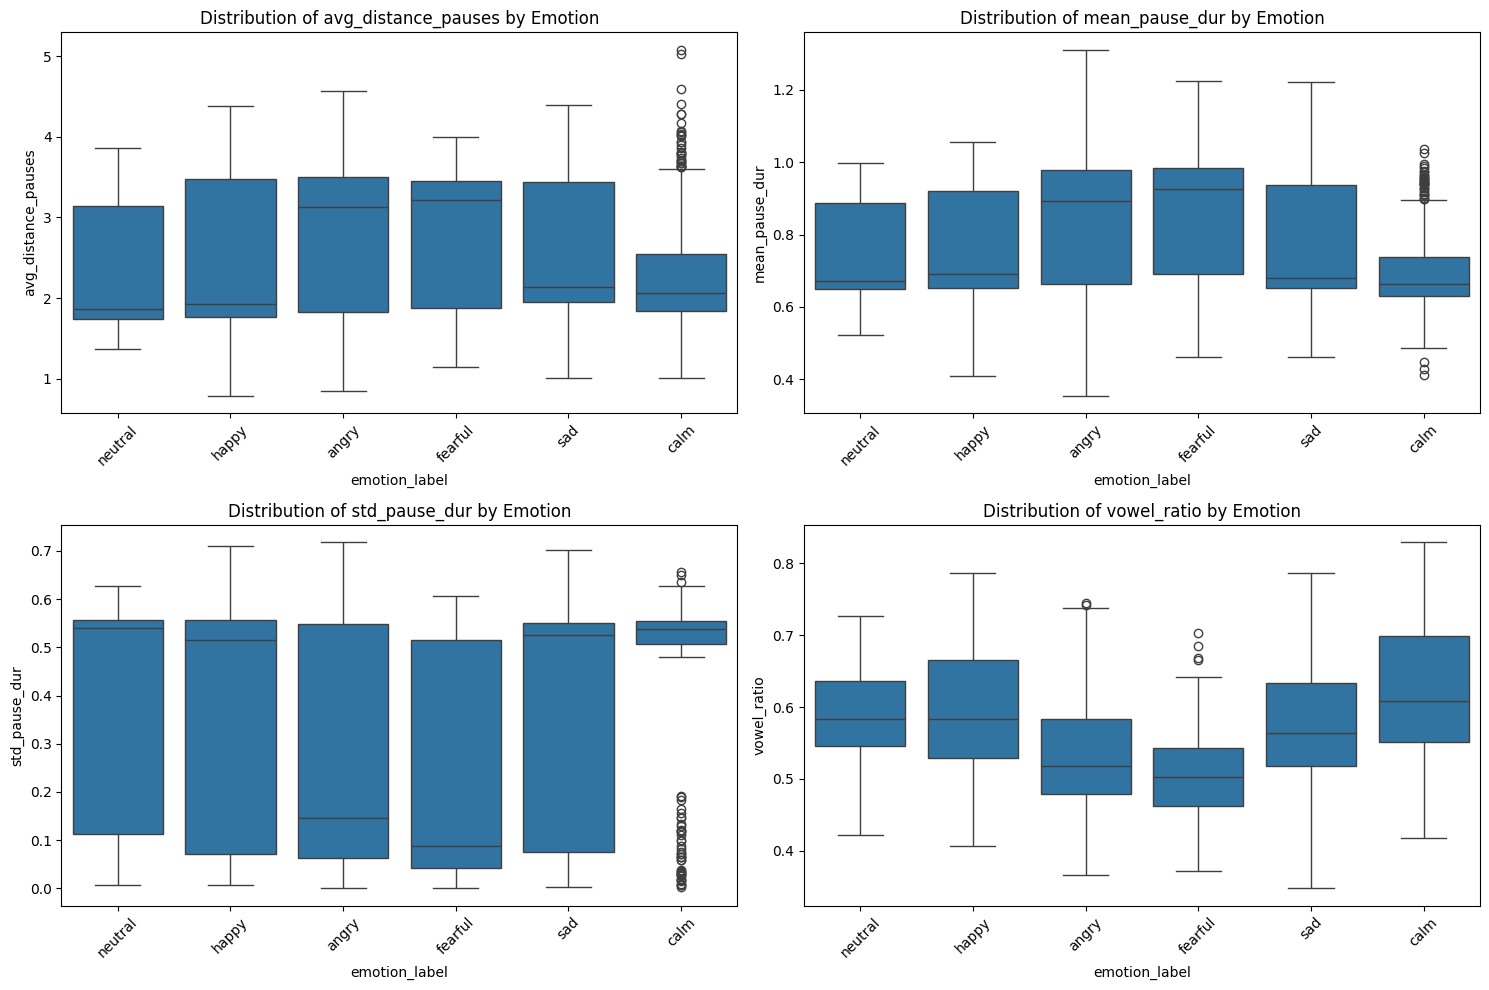

In [ ]:
# Label Mapping
emotion_map = {
    1: 'neutral', 2: 'calm', 3: 'happy', 4: 'sad',
    5: 'angry', 6: 'fearful'
}
df_merged['emotion_label'] = df_merged['emotion'].map(emotion_map)

pause_features = ['avg_distance_pauses', 'mean_pause_dur', 'std_pause_dur', 'vowel_ratio'] # Examine these extracted features

plt.figure(figsize=(15, 10))

for i, feature in enumerate(pause_features, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=df_merged, x='emotion_label', y=feature)
    plt.title(f'Distribution of {feature} by Emotion')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
df_merged = df_merged.drop(['emotion_label'], axis='columns')

## Z-speaker normalization

In [ ]:
def z_speaker_normalization(df, group_col, cols_to_norm):
    df_norm = df.copy()

    means = df_norm.groupby(group_col)[cols_to_norm].transform('mean')
    stds = df_norm.groupby(group_col)[cols_to_norm].transform('std')

   # Apply Z-score: (x - mean) / std
   # Add a very small number (1e-9) to the denominator to avoid division by zero
    df_norm[cols_to_norm] = (df_norm[cols_to_norm] - means) / (stds + 1e-9)

    return df_norm

In [ ]:
# Define which feature columns should be normalized
exclude_cols = ['filename', 'modality', 'vocal_channel', 'emotion', 'intensity',
       'statement', 'repetition', 'actor_id', 'gender', 'full_path']
feature_cols = [c for c in df_merged.columns if c not in exclude_cols and df_merged[c].dtype in ['float64', 'int64']]

df_normalized = z_speaker_normalization(df_merged, group_col='actor_id', cols_to_norm=feature_cols)

## Save all extracted features + metadata

In [ ]:
df_normalized.to_csv('/content/drive/MyDrive/df_ravdess_full(3).csv', index=False)

In [ ]:
df_normalized.columns.to_list()

['modality',
 'vocal_channel',
 'emotion',
 'intensity',
 'statement',
 'repetition',
 'actor_id',
 'gender',
 'F0semitoneFrom27.5Hz_sma3nz_amean',
 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm',
 'F0semitoneFrom27.5Hz_sma3nz_percentile20.0',
 'F0semitoneFrom27.5Hz_sma3nz_percentile50.0',
 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0',
 'F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2',
 'F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope',
 'F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope',
 'F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope',
 'F0semitoneFrom27.5Hz_sma3nz_stddevFallingSlope',
 'loudness_sma3_amean',
 'loudness_sma3_stddevNorm',
 'loudness_sma3_percentile20.0',
 'loudness_sma3_percentile50.0',
 'loudness_sma3_percentile80.0',
 'loudness_sma3_pctlrange0-2',
 'loudness_sma3_meanRisingSlope',
 'loudness_sma3_stddevRisingSlope',
 'loudness_sma3_meanFallingSlope',
 'loudness_sma3_stddevFallingSlope',
 'spectralFlux_sma3_amean',
 'spectralFlux_sma3_stddevNorm',
 'mfcc1_sma3_amean',
 'mfcc1_sma3_stdde

# VocalSet

**Setup**

1. Unzip the VocalSet dataset (sorted by technique) so that all audio files are located under:
/content/drive/MyDrive/data_by_technique/
2. For VocalSet, because audio files consist of isolated sustained vowels across musical scale patterns, individual note event boundaries from the dataset’s extended annotations (extended 2) are utilized. Place the extended 2/all_files.csv into /content/drive/MyDrive/data_by_technique/.

In [ ]:
from pathlib import Path

# 1. Συλλογή αρχείων
drive_path = "/content/drive/MyDrive/data_by_technique/**/*.wav"
files = glob.glob(drive_path, recursive=True)

data = []
base_path = Path("/content/drive/MyDrive/data_by_technique")

# 2. Επεξεργασία και εξαγωγή φακέλων/τεχνικών
for wave_file in tqdm(files, desc="Processing files"):
    file_path = Path(wave_file)

    # Σχετικό μονοπάτι ως προς τον αρχικό φάκελο
    try:
        rel_path = file_path.relative_to(base_path)
    except ValueError:
        rel_path = file_path

    # Ο αμέσως πάνω φάκελος ως Technique Label (π.χ. 'belt', 'vibrato')
    technique = file_path.parent.name

    data.append({
        'technique': technique,
        'relative_path': str(rel_path),
        'full_path': wave_file
    })

# 3. Δημιουργία DataFrame
vocal_set = pd.DataFrame(data)

# Επισκόπηση των πρώτων εγγραφών
print(vocal_set.head())

Processing files: 100%|██████████| 3612/3612 [00:00<00:00, 46887.95it/s]

   technique                           relative_path  \
0  vocal_fry     vocal_fry/f9_scales_vocal_fry_o.wav   
1  vocal_fry     vocal_fry/f9_scales_vocal_fry_u.wav   
2  vocal_fry  vocal_fry/f7_arpeggios_vocal_fry_u.wav   
3  vocal_fry  vocal_fry/f9_arpeggios_vocal_fry_a.wav   
4  vocal_fry  vocal_fry/f7_arpeggios_vocal_fry_o.wav   

                                           full_path  
0  /content/drive/MyDrive/data_by_technique/vocal...  
1  /content/drive/MyDrive/data_by_technique/vocal...  
2  /content/drive/MyDrive/data_by_technique/vocal...  
3  /content/drive/MyDrive/data_by_technique/vocal...  
4  /content/drive/MyDrive/data_by_technique/vocal...  


In [ ]:
df_phonemes = pd.read_csv('/content/drive/MyDrive/data_by_technique/all files.csv', index_col=False)

In [ ]:
files_phonemes = set(df_phonemes['File Name'])

# Extract base filenames from the path column
files_paths = set(
    vocal_set['relative_path'].apply(
        lambda x: os.path.splitext(os.path.basename(x))[0]
    )
)

# Find unique common filenames
common_files = files_phonemes.intersection(files_paths)

In [ ]:
# Remove files so that the analysis is restricted to isolated vowels

# Ensure clean_filename column exists
vocal_set['clean_filename'] = vocal_set['relative_path'].apply(
    lambda x: os.path.splitext(os.path.basename(x))[0]
)

# Define pattern for files to remove
exclude_pattern = 'dona|row|caro'

# Filter vocal_set directly
vocal_set = vocal_set[
    ~vocal_set['clean_filename'].str.contains(exclude_pattern, case=False)
].copy()

# Re-filter for common files
vocal_common = vocal_set[vocal_set['clean_filename'].isin(common_files)].copy()

# Get unique techniques
unique_techniques = vocal_common['technique'].unique()

print(f'Unique techniques in common files ({len(unique_techniques)} total):')
print(unique_techniques)
print(vocal_common.shape)

Unique techniques in common files (12 total):
['slow_forte' 'trill' 'slow_piano' 'messa' 'vibrato' 'lip_trill'
 'straight' 'belt' 'forte' 'fast_piano' 'breathy' 'fast_forte']
(2553, 4)


In [ ]:
smile = opensmile.Smile(
    feature_set=opensmile.FeatureSet.eGeMAPSv02,
    feature_level=opensmile.FeatureLevel.Functionals,
)

all_features = []

# Iterate directly over vocal_common DataFrame rows
for _, row in tqdm(
    vocal_common.iterrows(),
    total=len(vocal_common),
    desc="Processing files",
):
  wave_file = row["full_path"]
  filename = os.path.basename(wave_file)

  # Extract speaker ID (e.g., f1, m2)
  match = re.search(r"^([fm]\d{1,2})", filename.lower())
  if not match:
    continue

  speaker_id = match.group(1)

  # Use technique directly from vocal_common DataFrame
  technique = row["technique"]

  try:
    # Load and resample audio signal
    y, sr = librosa.load(wave_file, sr=target_sr)

    # Extract OpenSMILE features from signal array
    res_smile = smile.process_signal(y, sr)
    opensmile_features = res_smile.iloc[0].to_dict()

    # Extract custom/extra features
    extra_features = extract_extra_features(y, sr)

    # Combine metadata with features
    combined_features = {
        "filename": filename,
        "clean_filename": row.get("clean_filename", Path(filename).stem),
        "speaker_id": speaker_id,
        "technique": technique,
        "full_path": wave_file,
        **opensmile_features,
        **extra_features,
    }

    all_features.append(combined_features)

  except Exception as e:
    print(f" Error for {wave_file}: {e}")
    continue

# Create DataFrame and save
df_features = pd.DataFrame(all_features)

print(f"\nProcessing complete! {len(df_features)} samples created.")

Processing files: 100%|██████████| 2553/2553 [1:04:31<00:00,  1.52s/it]



Processing complete! 2553 samples created.


/tmp/ipykernel_2893/2852216266.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


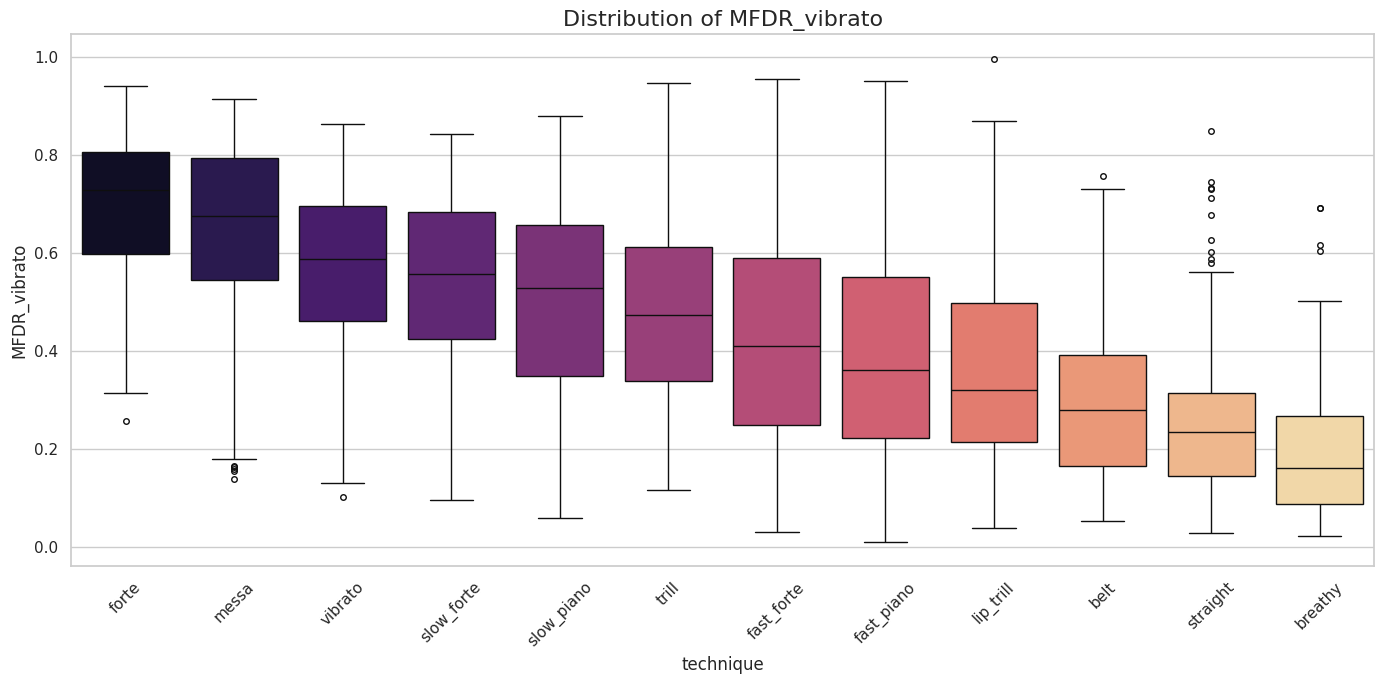

In [ ]:
sns.set_theme(style="whitegrid")

# Sort techniques by median
tech_order = df_features.groupby('technique')['MFDR_vibrato'].median().sort_values(ascending=False).index

plt.figure(figsize=(14, 7))

# Box Plot
sns.boxplot(
    data=df_features,
    x='technique',
    y='MFDR_vibrato',
    order=tech_order,
    palette='magma',
    fliersize=4 # Size of outlier dots
)

plt.title('Distribution of MFDR_vibrato', fontsize=16)
plt.xticks(rotation=45)
plt.ylabel('MFDR_vibrato')
plt.tight_layout()
plt.show()

## Vocal Technique Extractor

In [ ]:
target_samples = target_frames * hop_length

all_mel_chunks = []
all_pitch_chunks = []
chunk_metadata = []

for index, row in tqdm(df_features.iterrows(), total=len(df_features), desc="Processing tracks"):
    path = row['full_path']
    technique = row['technique']

    try:
        y, _ = librosa.load(path, sr=target_sr)
    except Exception as e:
        print(f"Error loading {path}: {e}")
        continue

    total_samples = len(y)

    for start_sample in range(0, total_samples, target_samples):
        end_sample = start_sample + target_samples
        chunk_audio = y[start_sample:end_sample]

        if len(chunk_audio) < target_samples:
            if len(chunk_audio) / target_samples < 0.3:
                continue
            chunk_audio = np.pad(chunk_audio, (0, target_samples - len(chunk_audio)), mode='constant')

        # 1. Mel-Spectrogram
        S = librosa.feature.melspectrogram(y=chunk_audio, sr=target_sr, n_mels=n_mels, n_fft=n_fft, hop_length=hop_length)
        S_dB = librosa.power_to_db(S, ref=np.max)

        # Resize/Fix frames to 128
        if S_dB.shape[1] > target_frames:
            S_dB = S_dB[:, :target_frames]
        elif S_dB.shape[1] < target_frames:
            S_dB = np.pad(S_dB, ((0, 0), (0, target_frames - S_dB.shape[1])))

        S_norm = np.clip((S_dB + 80) / 80, 0, 1)

        # 2. Pitch Contour (YIN)
        f0 = librosa.yin(y=chunk_audio, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C7'),
                         sr=target_sr, hop_length=hop_length)

        f0_norm = np.clip(f0 / librosa.note_to_hz('C7'), 0, 1)

        if len(f0_norm) > target_frames:
            f0_norm = f0_norm[:target_frames]
        elif len(f0_norm) < target_frames:
            f0_norm = np.pad(f0_norm, (0, target_frames - len(f0_norm)))

        all_mel_chunks.append(S_norm)
        all_pitch_chunks.append(f0_norm)

        # Save both path and technique for this specific chunk
        chunk_metadata.append({
            'path': path,
            'technique': technique
        })

X_mel_new = np.array(all_mel_chunks)[..., np.newaxis]
X_pitch_new = np.array(all_pitch_chunks)[..., np.newaxis]

df_metadata = pd.DataFrame(chunk_metadata)

print(f"{len(X_mel_new)} chunks ready!")

Processing tracks: 100%|██████████| 2553/2553 [05:25<00:00,  7.84it/s]


14155 chunks ready!


In [ ]:
# Load the model and get predictions
model = tf.keras.models.load_model("model_pitch_leaky (1).h5")
predictions = model.predict([X_mel_new, X_pitch_new])

# Create the predictions DataFrame
df_tech_features = pd.DataFrame(
    predictions,
    columns=['mix', 'falsetto', 'breathy', 'pharyngeal', 'glissando', 'vibrato']
)

# Convert your chunk_metadata list into a temporary DataFrame
df_meta = pd.DataFrame(chunk_metadata)

# Assign the columns to your features DataFrame
df_tech_features['full_path'] = df_meta['path']
df_tech_features['true_technique'] = df_meta['technique']

443/443 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step


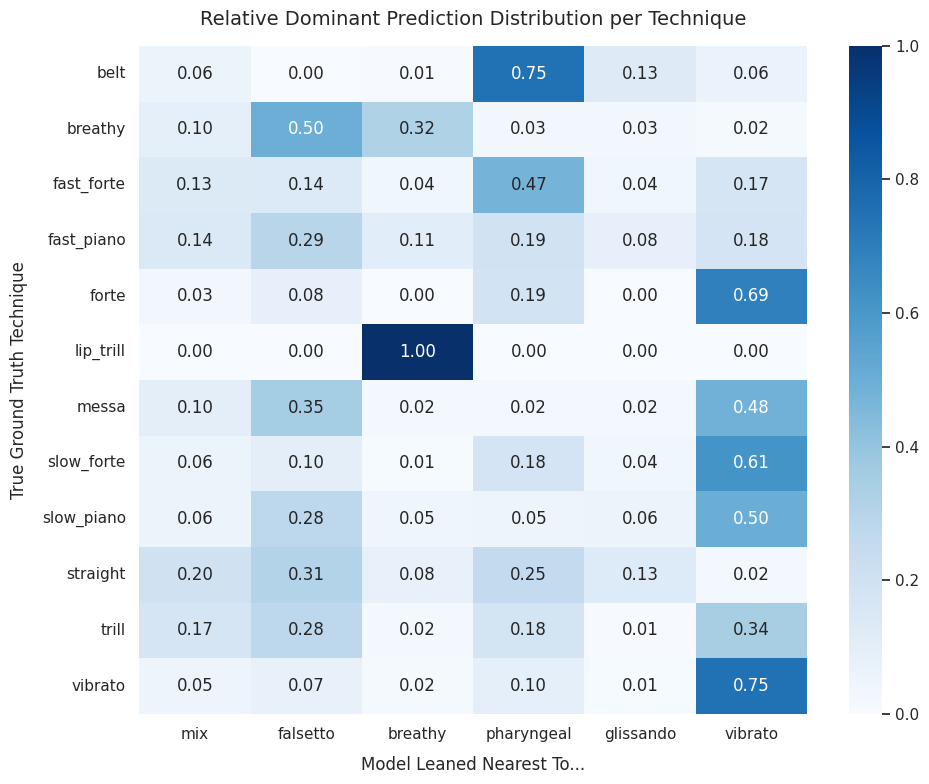

In [ ]:
# Aggregate Chunks to File Level
tech_columns = ['mix', 'falsetto', 'breathy', 'pharyngeal', 'glissando', 'vibrato']
agg_dict = {col: 'mean' for col in tech_columns}
agg_dict['true_technique'] = 'first'
df_file_level = df_tech_features.groupby('full_path').agg(agg_dict).reset_index()

# Calculate the overall global baseline bias for each model column
global_averages = df_file_level[tech_columns].mean()

# Subtract the global average to see which prediction *exceeds its typical behavior* the most
df_debiased = df_file_level[tech_columns].sub(global_averages, axis=1)

# Determine the True Dominant Relative Technique
df_file_level['relative_dominant'] = df_debiased.idxmax(axis=1)

# Cross-tabulate and Normalize Row-by-Row
df_counts = pd.crosstab(df_file_level['true_technique'], df_file_level['relative_dominant'])
df_counts = df_counts.reindex(columns=tech_columns, fill_value=0)
df_percentages = df_counts.div(df_counts.sum(axis=1), axis=0).fillna(0)

# Plot the Cleaned Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(
    df_percentages,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1
)
# We produce this table as an intermediate validation of the learned technique representations
plt.title('Relative Dominant Prediction Distribution per Technique', fontsize=14, pad=15)
plt.xlabel('Model Leaned Nearest To...', fontsize=12, labelpad=10)
plt.ylabel('True Ground Truth Technique', fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

## Vocal technique features

In [ ]:
tech_cols = ['vibrato', 'mix', 'falsetto', 'breathy', 'pharyngeal', 'glissando']
features_list = []

# Group by (filename)
for wav, group_raw in df_tech_features.groupby('full_path'):
    group = group_raw.copy()
    features = {'full_path': wav}

    # 1. Vocal Technique Statistics (Mean, Std, Max, Peak Factor)
    for tech in tech_cols:
        m = group[tech].mean()
        s = group[tech].std()
        mx = group[tech].max()

        features[f'{tech}_mean'] = m
        features[f'{tech}_std'] = s
        features[f'{tech}_max'] = mx
        # Peak Factor
        features[f'{tech}_peak_factor'] = mx / (m + 1e-7)

    group['dominant_tech'] = group[tech_cols].idxmax(axis=1)

    changes = (group['dominant_tech'] != group['dominant_tech'].shift()).sum() - 1
    features['num_tech_changes'] = max(0, changes)

    tech_sums = group[tech_cols].sum()
    if tech_sums.sum() > 0:
        tech_probs = tech_sums / tech_sums.sum()
        features['tech_entropy'] = entropy(tech_probs)
    else:
        features['tech_entropy'] = 0

    features_list.append(features)

df_structural_tech = pd.DataFrame(features_list)

print(f"Calculated vocal technique statistics for {len(df_structural_tech)} files.")

Calculated vocal technique statistics for 2553 files.


In [ ]:
df_final = df_features.merge(df_structural_tech, on='full_path', how='inner')

## Phonetic analysis

In [ ]:
df_phonemes = pd.read_csv('/content/drive/MyDrive/data_by_technique/all files.csv', index_col=False)

In [ ]:
cols_to_keep = ['File Name',
 ' Singer Name',' Technique',
 ' Vowel',
 ' Total Duration',
 ' Start time',
 ' End time', ' Duration',
 ' Type']
df_analysis = df_phonemes[cols_to_keep]

In [ ]:
df_analysis

,File Name,Singer Name,Technique,Vowel,Total Duration,Start time,End time,Duration,Type
0,f1_arpeggios_belt_c_a,f1,Belt_Harsh,a,7.27946,0.00000,0.34830,0.34830,Rest
1,f1_arpeggios_belt_c_a,f1,Belt_Harsh,a,7.27946,0.35991,1.01007,0.65016,Sound
2,f1_arpeggios_belt_c_a,f1,Belt_Harsh,a,7.27946,1.02168,1.88082,0.85914,Sound
3,f1_arpeggios_belt_c_a,f1,Belt_Harsh,a,7.27946,1.89243,2.62386,0.73143,Sound
4,f1_arpeggios_belt_c_a,f1,Belt_Harsh,a,7.27946,2.63547,3.65715,1.02168,Sound
...,...,...,...,...,...,...,...,...,...
36530,m9_scales_vibrato_u,m9,MoltoVibrato,u,23.33605,16.25397,17.43819,1.18422,Sound
36531,m9_scales_vibrato_u,m9,MoltoVibrato,u,23.33605,17.46141,18.62240,1.16099,Sound
36532,m9_scales_vibrato_u,m9,MoltoVibrato,u,23.33605,18.64562,19.87628,1.23066,Sound
36533,m9_scales_vibrato_u,m9,MoltoVibrato,u,23.33605,19.89950,22.52336,2.62386,Sound


In [ ]:
df_analysis['filename'] = df_analysis['File Name'].apply(lambda x: x if x.endswith('.wav') else f"{x}.wav")

base_path = "/content/drive/MyDrive/data_by_technique/"

# Recursively find all .wav files in the directory and subdirectories
all_files_in_drive = glob.glob(os.path.join(base_path, "**/*.wav"), recursive=True)

# Create a dictionary mapping the base filename (e.g., 'song.wav') to its full absolute path
path_map = {os.path.basename(f): f for f in all_files_in_drive}

# Map the full paths back to the DataFrame based on the normalized filename
df_analysis['full_path'] = df_analysis['filename'].map(path_map)

missing_files = df_analysis['full_path'].isna().sum()
if missing_files > 0:
    print(f"Warning: {missing_files} files were not found in Google Drive!")
else:
    print("All files matched successfully!")

print(df_analysis[['filename', 'full_path']].head())

All files matched successfully!
                    filename  \
0  f1_arpeggios_belt_c_a.wav   
1  f1_arpeggios_belt_c_a.wav   
2  f1_arpeggios_belt_c_a.wav   
3  f1_arpeggios_belt_c_a.wav   
4  f1_arpeggios_belt_c_a.wav   

                                           full_path  
0  /content/drive/MyDrive/data_by_technique/belt/...  
1  /content/drive/MyDrive/data_by_technique/belt/...  
2  /content/drive/MyDrive/data_by_technique/belt/...  
3  /content/drive/MyDrive/data_by_technique/belt/...  
4  /content/drive/MyDrive/data_by_technique/belt/...  


/tmp/ipykernel_820/4275980939.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_analysis['filename'] = df_analysis['File Name'].apply(lambda x: x if x.endswith('.wav') else f"{x}.wav")
/tmp/ipykernel_820/4275980939.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_analysis['full_path'] = df_analysis['filename'].map(path_map)


In [ ]:
def extract_phoneme_features(wave_file_path, df_phonemes):
    """
    wave_file_path: the full path of the file
    df_phonemes: df containing phoneme alignment
    """
    df_wav = df_phonemes[df_phonemes['full_path'] == wave_file_path].copy()

    if df_wav.empty:
        return {f: 0.0 for f in [
            'articulation_rate', 'std_phoneme_duration', 'phoneme_duration_cv',
            'pause_ratio', 'mean_phoneme_duration', 'vowel_ratio', 'consonant_ratio',
            'mean_pause_dur', 'std_pause_dur'
        ]}

    # In VocalSet we have type either Rest or Sound
    speech_df = df_wav[df_wav[' Type'] != 'Rest']
    pause_df = df_wav[df_wav[' Type'] == 'Rest']

    total_duration = df_wav[' Duration'].sum()
    vocalized_duration = speech_df[' Duration'].sum()

    mean_dur = float(speech_df[' Duration'].mean()) if not speech_df.empty else 0.0
    std_dur = float(speech_df[' Duration'].std()) if len(speech_df) > 1 else 0.0

    mean_pause_dur = float(pause_df[' Duration'].mean()) if not pause_df.empty else 0.0
    std_pause_dur = float(pause_df[' Duration'].std()) if len(pause_df) > 1 else 0.0

    features = {
        "articulation_rate": len(speech_df) / vocalized_duration if vocalized_duration > 0 else 0.0,
        "mean_phoneme_duration": mean_dur,
        "std_phoneme_duration": std_dur,
        "phoneme_duration_cv": std_dur / mean_dur if mean_dur > 0 else 0.0,
        "pause_ratio": pause_df[' Duration'].sum() / total_duration if total_duration > 0 else 0.0,
        "mean_pause_dur": mean_pause_dur,
        "std_pause_dur": std_pause_dur,
        "vowel_ratio": 1.0,
        "consonant_ratio": 0.0
    }

    return features

all_paths = df_analysis['full_path'].unique()
vocal_features_list = [extract_phoneme_features(f, df_analysis) for f in all_paths]

df_phoneme_final = pd.DataFrame(vocal_features_list)
df_phoneme_final.insert(0, 'full_path', all_paths)


In [ ]:
df_vocalset = df_final.merge(df_phoneme_final, on='full_path', how='inner')

In [ ]:
df_vocalset.shape

(2553, 151)

## Z-speaker normalization

In [ ]:
exclude_cols = ['filename', 'speaker_id', 'technique', 'full_path']
feature_cols = [c for c in df_vocalset.columns if c not in exclude_cols and df_vocalset[c].dtype in ['float64', 'int64']]

df_normalized = z_speaker_normalization(df_vocalset, group_col='speaker_id', cols_to_norm=feature_cols)

In [ ]:
df_normalized.to_csv('/content/drive/MyDrive/vocalset_final_check.csv', index=False)

# GTSinger

In [ ]:
!gdown --folder "https://drive.google.com/drive/folders/1xcdvCxNAEEfJElt7sEP-xT8dMKxn1_Lz?usp=drive_link"

Retrieving folder contents
Processing file 1ZuY8Bj0djxK0gQHnX9ur5anUgDusZ8xp Chinese.zip
Processing file 14YYGOxyIjjR-oQ5gUbZnDRgW1mPsA3Ow dataset_license.md
Processing file 1DK1vnTs_d9JD7Xya4U5CEaXszIWyboFv English.zip
Processing file 1c-wf0Sx_BYWlW7uDSvUZt6S9-2bdmd2A French.zip
Processing file 18G4ByGGD0vV8dunDZ1NrQKubqPLuD-Jq German.zip
Processing file 1fxKD95WKbBRtLC0bTF8YcnfwHTRYJRuJ Italian.zip
Processing file 1wu4ccoht3-Yb_UIGgDGhPG-6T8cwFd70 Japanese.zip
Processing file 1hwROisMOpUEAI5d9RgHi_V5fuW59UB4u Korean.zip
Processing file 1tWaYIZLrquG_y2Nwycex4CV1a8SfqJpo processed.zip
Processing file 12_bcpmL4NGWy6bZz-e8nrvV2_MbQCise Russian.zip
Processing file 1MYGtSwSMXjkQ_93ZeQZ5Z2VJ5NX7WNu2 Spanish.zip
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1ZuY8Bj0djxK0gQHnX9ur5anUgDusZ8xp
From (redirected): https://drive.google.com/uc?id=1ZuY8Bj0djxK0gQHnX9ur5anUgDusZ8x

## Data preprocessing

In [ ]:
!unzip "/content/GTSinger/English.zip" -d "/content/GTSinger/English"

Η έξοδος ροής περικόπηκε στις τελευταίες 5000 γραμμές.
  inflating: /content/GTSinger/English/English/EN-Alto-2/Breathy/My Heart Will Go On/Paired_Speech_Group/0004.json  
  inflating: /content/GTSinger/English/English/EN-Alto-2/Breathy/My Heart Will Go On/Paired_Speech_Group/0003.wav  
  inflating: /content/GTSinger/English/English/EN-Alto-2/Breathy/My Heart Will Go On/Paired_Speech_Group/0001.wav  
  inflating: /content/GTSinger/English/English/EN-Alto-2/Breathy/My Heart Will Go On/Paired_Speech_Group/0000.wav  
  inflating: /content/GTSinger/English/English/EN-Alto-2/Breathy/My Heart Will Go On/Paired_Speech_Group/0008.json  
  inflating: /content/GTSinger/English/English/EN-Alto-2/Breathy/My Heart Will Go On/Paired_Speech_Group/0003.json  
  inflating: /content/GTSinger/English/English/EN-Alto-2/Breathy/My Heart Will Go On/Paired_Speech_Group/0002.json  
  inflating: /content/GTSinger/English/English/EN-Alto-2/Breathy/My Heart Will Go On/Paired_Speech_Group/0001.json  
  inflating:

In [ ]:
def extract_phoneme_rows(json_path, meta):
    try:
        with open(json_path, 'r', encoding="utf-8", errors="ignore") as f:
            content = f.read().strip()
            if not content:
                return []  # empty file
            data = json.loads(content)
    except json.JSONDecodeError:
        return []  # corrupted JSON
    except Exception as e:
        print("SKIP:", json_path, e)
        return []

    rows = []

    for item in data:
        base_info = {
            "word": item.get("word"),
            "word_start": item.get("start_time"),
            "word_end": item.get("end_time"),
            "emotion": item.get("emotion"),
            "pace": item.get("pace"),
            "range_label": item.get("range"),
            "singing_method": item.get("singing_method"),
        }

        # Only add metadata fields that are NOT None
        for k, v in meta.items():
            if v is not None:
                base_info[k] = v

        ph_list = item.get("ph", [])
        n = len(ph_list)

        ph_start = item.get("ph_start", [None] * n)
        ph_end   = item.get("ph_end",   [None] * n)

        mix_list         = item.get("mix",         ["0"] * n)
        falsetto_list    = item.get("falsetto",    ["0"] * n)
        breathy_list     = item.get("breathy",     ["0"] * n)
        pharyngeal_list  = item.get("pharyngeal",  ["0"] * n)
        glissando_list   = item.get("glissando",   ["0"] * n)
        vibrato_list     = item.get("vibrato",     ["0"] * n)

        notes = item.get("note", [])
        note_val = notes[0] if notes else None

        for i, ph in enumerate(ph_list):
            st = ph_start[i]
            en = ph_end[i]
            dur = (en - st) if st is not None and en is not None else None

            row = base_info.copy()
            row.update({
                "phoneme": ph,
                "ph_start": st,
                "ph_end": en,
                "duration": dur,
                "note": note_val,
                "mix": mix_list[i],
                "falsetto": falsetto_list[i],
                "breathy": breathy_list[i],
                "pharyngeal": pharyngeal_list[i],
                "glissando": glissando_list[i],
                "vibrato": vibrato_list[i],
            })

            rows.append(row)

    return rows


def load_gtsinger(root_folder):

    all_rows = []

    json_paths = []
    for root, _, files in os.walk(root_folder):
        for f in files:
            if f.endswith(".json"):
                json_paths.append(os.path.join(root, f))

    for json_path in tqdm(json_paths, desc="Loading JSONs"):
        parts = json_path.replace(root_folder, "").strip(os.sep).split(os.sep)

        # expected: EN-Alto-1 / Technique / SongTitle / Group / file.json
        try:
            lang_range      = parts[0]
            technique       = parts[1]
            song_title      = parts[2]
            group_folder    = parts[3]
            file_name       = parts[4]
        except IndexError:
            print("BAD PATH:", parts)
            continue

        language = lang_range.split("-")[0]
        range_folder = "-".join(lang_range.split("-")[1:])

        meta = {
            "language": language,
            "range_folder": range_folder,
            "technique_folder": technique,
            "song_title": song_title,
            "group_folder": group_folder,
            "json_file": file_name,
        }

        rows = extract_phoneme_rows(json_path, meta)
        all_rows.extend(rows)

    return pd.DataFrame(all_rows)


In [ ]:
df_phonemes_en = load_gtsinger("/content/GTSinger/English/English")

Loading JSONs: 100%|██████████| 6892/6892 [00:07<00:00, 958.26it/s] 


In [ ]:
df_phonemes_en['wav_path'] = (
    "/content/GTSinger/English/English/EN-" +
    df_phonemes_en['range_folder'].astype(str) + "/" +
    df_phonemes_en['technique_folder'].astype(str) + "/" +
    df_phonemes_en['song_title'].astype(str) + "/" +
    df_phonemes_en['group_folder'].astype(str) + "/" +
    df_phonemes_en['json_file'].str.replace(".json", ".wav")
)


In [ ]:
def extract_word_rows(json_path, meta):
    with open(json_path, 'r') as f:
        data = json.load(f)

    rows = []

    for item in data:
        base_info = {
            "word": item.get("word"),
            "word_start": item.get("start_time"),
            "word_end": item.get("end_time"),
            "emotion": item.get("emotion"),
            "pace": item.get("pace"),
            "range_label": item.get("range"),
            "singing_method": item.get("singing_method"),
            "json_path": json_path
        }

        base_info.update(meta)
        rows.append(base_info)

    return rows

def load_gtsinger_words(root_folder):

    all_rows = []

    json_paths = []
    for root, _, files in os.walk(root_folder):
        for f in files:
            if f.endswith(".json"):
                json_paths.append(os.path.join(root, f))

    for json_path in tqdm(json_paths, desc="Loading JSONs"):
        parts = json_path.replace(root_folder, "").strip(os.sep).split(os.sep)

        try:
            lang_range      = parts[0]
            technique       = parts[1]
            song_title      = parts[2]
            group_folder    = parts[3]
            file_name       = parts[4]
        except IndexError:
            print("BAD PATH:", parts)
            continue

        language = lang_range.split("-")[0]
        range_folder = "-".join(lang_range.split("-")[1:])

        meta = {
            "language": language,
            "range_folder": range_folder,
            "technique_folder": technique,
            "song_title": song_title,
            "group_folder": group_folder,
            "json_file": file_name,
        }

        rows = extract_word_rows(json_path, meta)
        all_rows.extend(rows)

    return pd.DataFrame(all_rows)


In [ ]:
df_words_en = load_gtsinger_words("/content/GTSinger/English/English")

Loading JSONs: 100%|██████████| 6892/6892 [00:01<00:00, 5709.23it/s]


In [ ]:
df_words_en["wav_path"] = df_words_en["json_path"].str.replace(".json", ".wav")

# Global labels per wav_path (keep the first row)
df_labels = df_words_en.groupby("wav_path").first()[[
    "emotion",
    "pace",
    "range_label",
    "singing_method",
    "language",
    "range_folder",
    "technique_folder",
    "song_title",
    "group_folder",
    "json_file"
]].reset_index()

# 3. Lyrics aggregation (όλα τα words ενωμένα)
df_lyrics = (
    df_words_en
    .groupby("wav_path")["word"]
    .apply(lambda w: " ".join(w.dropna().tolist()))
    .reset_index()
    .rename(columns={"word": "lyrics"})
)

# Merge labels + lyrics -> df_segments
df_segments_en = df_labels.merge(df_lyrics, on="wav_path")


In [ ]:
df_segments_en = df_segments_en[df_segments_en['group_folder'] != 'Paired_Speech_Group'] # We remove the paired-speech samples

In [ ]:
df_phonemes_en = df_phonemes_en[df_phonemes_en['group_folder'] != 'Paired_Speech_Group']

## Feature extraction


In [ ]:
# df_phonemes contain the phonemes extracted from the English, French and German samples
df_phonemes = pd.read_csv('/content/drive/MyDrive/df_phonemes_all_extracted.csv')

In [ ]:
df_phonemes.shape

(416667, 27)

In [ ]:
# df_phonemes contain the annotated segments from the English, French and German samples
df_segments = pd.read_csv('/content/drive/MyDrive/df_segments_extracted.csv')

In [ ]:
df_segments.shape

(10657, 12)

In [ ]:
df_segments['performance_folder'] = df_segments['wav_path'].apply(lambda x: os.path.dirname(x))

## Vocal Technique

In [ ]:
tech_cols = ['vibrato', 'mix', 'falsetto', 'breathy', 'pharyngeal', 'glissando']

for col in tech_cols:
    df_phonemes[col] = pd.to_numeric(df_phonemes[col], errors='coerce').fillna(0)

df_phonemes['duration'] = pd.to_numeric(df_phonemes['duration'], errors='coerce').fillna(0)

features_list = []

grouped = df_phonemes.groupby('wav_path')

for wav, group_raw in tqdm(grouped, desc="Extracting Technique Features"):
    group = group_raw.copy()
    features = {'wav_path': wav}

    # Duration of the clip
    total_dur = group['duration'].sum()

    for tech in tech_cols:
        # Weighted Mean: What is the duration (percentage) of the technique's presence in the total time?
        if total_dur > 0:
            w_mean = (group[tech] * group['duration']).sum() / total_dur
        else:
            w_mean = 0

        # Note: The std is calculated on the binary values per phoneme
        w_std = group[tech].std() if len(group) > 1 else 0
        w_max = group[tech].max()

        # Peak Factor: Max / Weighted Mean
        w_pf = w_max / w_mean if w_mean > 0 else 0

        features[f'{tech}_mean'] = w_mean
        features[f'{tech}_std'] = w_std
        features[f'{tech}_max'] = w_max
        features[f'{tech}_peak_factor'] = w_pf

    # Create the techniques matrix (phonemes x techniques)
    tech_matrix = group[tech_cols].values
    # Count how many times the state changes (any of the 6 techniques)
    # from one phoneme to the next
    if len(tech_matrix) > 1:
        changes = (np.diff(tech_matrix, axis=0) != 0).any(axis=1).sum()
    else:
        changes = 0
    features['num_tech_changes'] = int(changes)

    # Use the total duration of each technique for the distribution
    tech_durations = [(group[t] * group['duration']).sum() for t in tech_cols]
    sum_all_tech_durs = sum(tech_durations)

    if sum_all_tech_durs > 0:
       # Probability of each technique's occurrence based on time
        probs = [d / sum_all_tech_durs for d in tech_durations]
        features['tech_entropy'] = entropy(probs)
    else:
        features['tech_entropy'] = 0

    features_list.append(features)

df_technique_features = pd.DataFrame(features_list)

df_technique_features = df_technique_features.fillna(0)

print(f"Features extracted for {len(df_technique_features)} audio files.")
print(df_technique_features.head())

Extracting Technique Features: 100%|██████████| 10657/10657 [00:40<00:00, 261.95it/s]


Features extracted for 10657 audio files.
                                            wav_path  vibrato_mean  \
0  /content/GTSinger/English/English/EN-Alto-1/Br...           0.0   
1  /content/GTSinger/English/English/EN-Alto-1/Br...           0.0   
2  /content/GTSinger/English/English/EN-Alto-1/Br...           0.0   
3  /content/GTSinger/English/English/EN-Alto-1/Br...           0.0   
4  /content/GTSinger/English/English/EN-Alto-1/Br...           0.0   

   vibrato_std  vibrato_max  vibrato_peak_factor  mix_mean   mix_std  mix_max  \
0          0.0            0                  0.0  0.748429  0.331662        1   
1          0.0            0                  0.0  0.837806  0.254972        1   
2          0.0            0                  0.0  0.822219  0.294245        1   
3          0.0            0                  0.0  0.796796  0.358569        1   
4          0.0            0                  0.0  0.423830  0.503761        1   

   mix_peak_factor  falsetto_mean  ...  pharyngeal

## Phonetic analysis

In [ ]:
unique_phonemes = df_phonemes[df_phonemes['language'] == 'EN']['phoneme'].unique()
print(unique_phonemes)

['OW1' 'DH' 'AH0' 'R' 'IY1' 'Z' 'N' 'AY1' 'HH' 'L' 'D' 'AA1' '<SP>' 'AW1'
 'ER0' 'W' 'G' 'TH' 'UW1' 'M' 'AE1' 'IH1' 'IY0' 'EH1' 'S' 'SH' 'AH1' 'IH0'
 'NG' 'T' 'Y' 'F' 'K' 'EY1' 'V' 'CH' '<AP>' 'B' 'AO1' 'UH1' 'P' 'UH0'
 'EY2' 'ER1' 'UH2' 'AE2' 'EH2' 'JH' 'AH2' 'EH0' 'IH2' 'AO0' 'AY2' 'OY1'
 'AO2' 'OW0' 'AY0' 'OW2' 'EY0' 'UW0' 'IY2' 'ZH' 'AA2' 'ER2' 'AW2' 'AE0'
 'UW2']


In [ ]:
unique_phonemes = df_phonemes[df_phonemes['language'] == 'FR']['phoneme'].unique()
print(unique_phonemes)

['e' 'ʒ' 'ə' 't' 'ɛ' 'y' 'n' 'ʃ' 'ɔ' 'z' 'a' 'w' '<AP>' 'k' 'ʁ' 'm' '<SP>'
 'v' 'p' 'ɛ̃' 'ɡ' 's' 'u' 'ɑ̃' 'd' 'ɔ̃' 'o' 'l' 'œ' 'i' 'ʎ' 'b' 'ɑ' 'j'
 'f' 'ɲ' 'c' 'ø' 'ɥ' 'mʲ' 'ŋ' 'tʃ' 'ɟ']


In [ ]:
unique_phonemes = df_phonemes[df_phonemes['language'] == 'DE']['phoneme'].unique()
print(unique_phonemes)

['ʃ' 'p' 'ɪ' 'ts' 'ə' 'n' 't' 'aj' '<AP>' 'd' 'eː' 'aː' 'm' 'ɐ' 'l' 'iː'
 's' 'h' 'a' 'ʁ' 'tʰ' 'uː' 'ç' 'z' 'oː' 'ʊ' 'ɛ' '<SP>' 'v' 'f' 'k' 'b' 'ɡ'
 'ɔ' 'ɟ' 'kʰ' 'yː' 'aw' 'ŋ' 'x' 'n̩' 'ʏ' 'œ' 'øː' 'm̩' 'j' 'ɔʏ' 'pʰ' 'pf'
 'tʃ' 'cʰ' 'ɲ']


In [ ]:
def extract_phoneme_features(filename, df):
    df_wav = df[df['wav_path'] == filename].copy()

    if df_wav.empty:
        return {}

    def calc_avg_dist(temp_df):
        if len(temp_df) < 2: return 0.0
        return temp_df['ph_start'].diff().mean()

    language = df_wav['language'].iloc[0]

    vowel_maps = {
        'EN': r'^(AA|AE|AH|AO|AW|AY|EH|ER|EY|IH|IY|OW|OY|UH|UW)\d?$',
        'FR': {'e', 'ə', 'ɛ', 'y', 'ɔ', 'a', 'ɛ̃', 'u', 'ɑ̃', 'ɔ̃', 'o', 'œ', 'i', 'ɑ', 'ø'},
        'DE': {'ɪ', 'ə', 'aj', 'eː', 'aː', 'ɐ', 'iː', 'a', 'uː', 'oː', 'ʊ', 'ɛ', 'ɔ', 'yː', 'aw', 'ʏ', 'œ', 'øː', 'ɔʏ'}
    }
    # Is_Pause column based on phoneme_type column
    df_wav['Is_Pause'] = df_wav['phoneme'].isin(['<AP>', '<SP>']).astype(int)    # Subset of phonemes (speech)
    speech_df = df_wav[df_wav['Is_Pause'] == 0].copy()
    pause_df = df_wav[df_wav['Is_Pause'] == 1].copy()

    if speech_df.empty:
        return {k: 0.0 for k in ["phoneme_duration_cv", "articulation_rate", 'mean_pause_duration', 'std_pause_duration',
                                 "mean_phoneme_duration", "std_phoneme_duration", "pause_ratio", "vowel_ratio", "avg_distance_pauses"]}

    if language == 'EN':
        speech_df['is_vowel'] = speech_df['phoneme'].str.match(vowel_maps['EN'])
    else:
        current_vowels = vowel_maps.get(language, set())
        speech_df['is_vowel'] = speech_df['phoneme'].isin(current_vowels)


    mean_dur = float(speech_df['duration'].mean())
    std_dur = float(speech_df['duration'].std() if len(speech_df) > 1 else 0.0)
    total_time = df_wav['ph_end'].max() - df_wav['ph_start'].min()
    total_duration = df_wav['duration'].sum()
    vocalized_duration = speech_df['duration'].sum()
    vowel_dur = speech_df[speech_df['is_vowel'] == True]['duration'].sum()

    if not pause_df.empty:
        mean_pause_dur = float(pause_df['duration'].mean())
        std_pause_dur = float(pause_df['duration'].std()) if len(pause_df) > 1 else 0.0
        avg_dist_pauses = calc_avg_dist(pause_df)
    else:
        mean_pause_dur = std_pause_dur = avg_dist_pauses = 0.0

    features = {
        "rel_mean_phoneme_duration": mean_dur / total_time if total_time > 0 else 0.0,
        "phoneme_duration_cv": std_dur / mean_dur if mean_dur > 0 else 0.0,
        "mean_pause_duration": mean_pause_dur,
        "std_pause_duration": std_pause_dur,
        "articulation_rate": len(speech_df) / vocalized_duration if vocalized_duration > 0 else 0.0,
        "mean_phoneme_duration": mean_dur,
        "std_phoneme_duration": std_dur,
        "avg_distance_pauses": avg_dist_pauses,
        "vowel_ratio": vowel_dur / vocalized_duration if vocalized_duration > 0 else 0.0,
        "pause_ratio": (total_duration - vocalized_duration) / total_duration if total_duration > 0 else 0.0,
    }

    return features

In [ ]:
unique_wavs = df_phonemes['wav_path'].unique()

phoneme_feats_list = []

for wav_path in tqdm(unique_wavs, desc='Computing detailed phoneme features...'):

    features = extract_phoneme_features(wav_path, df_phonemes)

    if features:
        features['wav_path'] = wav_path
        phoneme_feats_list.append(features)

df_phoneme_feats = pd.DataFrame(phoneme_feats_list)

print(df_phoneme_feats[['wav_path', 'phoneme_duration_cv', 'articulation_rate']].head())

Computing detailed phoneme features...: 100%|██████████| 10657/10657 [06:43<00:00, 26.38it/s]

                                            wav_path  phoneme_duration_cv  \
0  /content/GTSinger/English/English/EN-Tenor-1/V...             1.712458   
1  /content/GTSinger/English/English/EN-Tenor-1/V...             2.386814   
2  /content/GTSinger/English/English/EN-Tenor-1/V...             2.447377   
3  /content/GTSinger/English/English/EN-Tenor-1/V...             2.092867   
4  /content/GTSinger/English/English/EN-Tenor-1/V...             1.984574   

   articulation_rate  
0           1.876407  
1           3.499125  
2           3.570549  
3           3.018542  
4           3.522081  


In [ ]:
df_phon_tech = df_phoneme_feats.merge(df_technique_features, on='wav_path', how='left')


## Extract opensmile+extra features

In [ ]:
def process_segments_combined(main_df):
    final_data = []
    unique_wavs = main_df['wav_path'].unique()

    # OpenSMILE
    smile = opensmile.Smile(
        feature_set=opensmile.FeatureSet.eGeMAPSv02,
        feature_level=opensmile.FeatureLevel.Functionals
    )

    for wav_path in tqdm(unique_wavs, desc="Global Feature Extraction"):
        try:
            y, sr = librosa.load(wav_path, sr=22050)
            if len(y) < int(0.15 * sr): continue

            # extract opensmile features
            smile_feats_df = smile.process_signal(y, sr)
            smile_dict = smile_feats_df.iloc[0].to_dict()

            # extract extra features (librosa & crepe)
            extra_feats = extract_extra_features(y, sr)

            # Metadata
            metadata_row = main_df[main_df['wav_path'] == wav_path].iloc[0]

            meta_dict = metadata_row.to_dict()

            combined_row = {**meta_dict, **smile_dict, **extra_feats}
            final_data.append(combined_row)

        except Exception as e:
            print(f"Error processing {wav_path}: {e}")

    return pd.DataFrame(final_data)

df_acoustic_feats = process_segments_combined(df_segments)
df_acoustic_feats.to_csv('/content/drive/MyDrive/acoustic_gts_check.csv', index=False)

Global Feature Extraction: 100%|██████████| 10657/10657 [3:07:20<00:00,  1.05s/it]


In [ ]:
df_acoustic_feats = pd.read_csv('/content/drive/MyDrive/acoustic_gts_check.csv')

In [ ]:
# Remove rows with unextractable features
df_acoustic_feats.dropna(subset=['MFDR_slow'], inplace=True)

In [ ]:
df_acoustic_feats.shape

(10656, 124)

In [ ]:
df_gtsinger = df_acoustic_feats.merge(df_phon_tech, on='wav_path', how ="left")
df_gtsinger['unique_singer_id'] = df_gtsinger['language'] + "-" + df_gtsinger['range_folder']

## Z-Speaker Normalization

In [ ]:
metadata_cols = [
    'wav_path', 'emotion', 'pace', 'range_label', 'singing_method',
    'language', 'range_folder', 'technique_folder', 'song_title',
    'group_folder', 'json_file', 'lyrics', 'performance_folder', 'unique_singer_id'
]

cols_to_scale = [c for c in df_gtsinger.columns if c not in metadata_cols]
# z-speaker normalization
for feat in cols_to_scale:
    m = df_gtsinger.groupby('unique_singer_id')[feat].transform('mean')
    s = df_gtsinger.groupby('unique_singer_id')[feat].transform('std')

    df_gtsinger[feat] = (df_gtsinger[feat] - m) / (s + 1e-9)

print("Normalization complete!")

Normalization complete!


In [ ]:
df_gtsinger.to_csv('/content/drive/MyDrive/df_gtsinger_check(3).csv', index=False)